In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

print("TensorFlow Version:", tf.__version__)

# Load MNIST Handwritten Digits Dataset (60,000 train / 10,000 test)
(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.mnist.load_data()

# Flatten 28x28 grayscale images into 784-dimensional vectors & normalize pixel values to [0, 1]
X_train = X_train_raw.reshape(-1, 784).astype("float32") / 255.0
X_test = X_test_raw.reshape(-1, 784).astype("float32") / 255.0

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

I0000 00:00:1794550428.146443     211 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow Version: 2.21.0
X_train shape: (60000, 784) | y_train shape: (60000,)
X_test shape:  (10000, 784)  | y_test shape:  (10000,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)


Training Config 1 (LR=0.001, BS=128)...


... (3 outputs left out)


Training Config 3 (LR=0.0005, BS=64)...


W0000 00:00:1794550510.912654     211 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.



--- Neural Network Hyperparameter Tuning Results (Test Set, N=10,000) ---


,Configuration,Learning Rate,Batch Size,Final Val Acc,Test Loss,Test Accuracy
0,"Config 1 (LR=0.001, BS=128)",0.0010,128,0.9832,0.0662,0.9824
1,"Config 2 (LR=0.005, BS=64)",0.0050,64,0.9760,0.1151,0.9738
2,"Config 3 (LR=0.0005, BS=64)",0.0005,64,0.9812,0.0646,0.9818


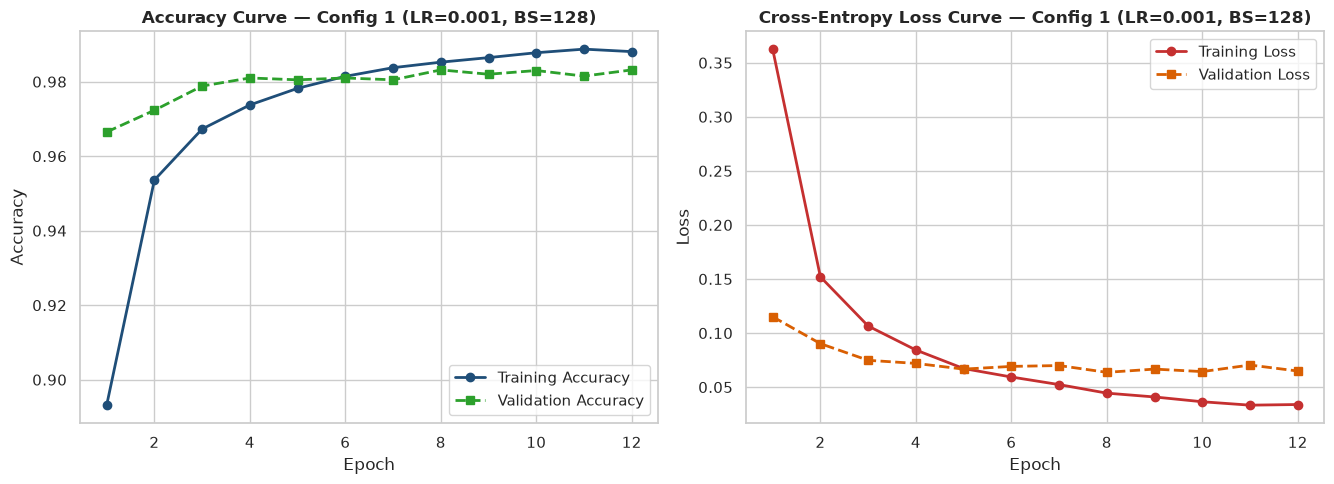

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility seed
tf.random.set_seed(42)
np.random.seed(42)

def build_mlp(learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Print architecture summary for the baseline network
sample_model = build_mlp()
sample_model.summary()

# Hyperparameter Tuning Grid (learning_rate & batch_size)
configs = [
    {"name": "Config 1 (LR=0.001, BS=128)", "lr": 0.001, "bs": 128},
    {"name": "Config 2 (LR=0.005, BS=64)",  "lr": 0.005, "bs": 64},
    {"name": "Config 3 (LR=0.0005, BS=64)", "lr": 0.0005, "bs": 64}
]

histories = {}
tuning_results = []

for cfg in configs:
    print(f"\nTraining {cfg['name']}...")
    tf.random.set_seed(42)
    m = build_mlp(learning_rate=cfg["lr"])
    hist = m.fit(
        X_train, y_train,
        epochs=12,
        batch_size=cfg["bs"],
        validation_split=0.10,
        verbose=0
    )
    test_loss, test_acc = m.evaluate(X_test, y_test, verbose=0)
    histories[cfg["name"]] = hist.history
    tuning_results.append({
        "Configuration": cfg["name"],
        "Learning Rate": cfg["lr"],
        "Batch Size": cfg["bs"],
        "Final Val Acc": round(hist.history["val_accuracy"][-1], 4),
        "Test Loss": round(test_loss, 4),
        "Test Accuracy": round(test_acc, 4)
    })

df_nn_eval = pd.DataFrame(tuning_results)
print("\n--- Neural Network Hyperparameter Tuning Results (Test Set, N=10,000) ---")
display(df_nn_eval)

# Plot Training & Validation Accuracy and Loss Curves for the Top Model (Config 3 / Config 1)
best_cfg_name = df_nn_eval.sort_values(by="Test Accuracy", ascending=False).iloc[0]["Configuration"]
best_hist = histories[best_cfg_name]
epochs_range = range(1, len(best_hist["accuracy"]) + 1)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Left Panel: Accuracy Curves
axes[0].plot(epochs_range, best_hist["accuracy"], "o-", color="#1f4e78", lw=2, label="Training Accuracy")
axes[0].plot(epochs_range, best_hist["val_accuracy"], "s--", color="#2ca02c", lw=2, label="Validation Accuracy")
axes[0].set_title(f"Accuracy Curve — {best_cfg_name}", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")

# Right Panel: Loss Curves
axes[1].plot(epochs_range, best_hist["loss"], "o-", color="#c53030", lw=2, label="Training Loss")
axes[1].plot(epochs_range, best_hist["val_loss"], "s--", color="#d95f02", lw=2, label="Validation Loss")
axes[1].set_title(f"Cross-Entropy Loss Curve — {best_cfg_name}", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

In [3]:
print(df_nn_eval.to_string(index=False))

              Configuration  Learning Rate  Batch Size  Final Val Acc  Test Loss  Test Accuracy
Config 1 (LR=0.001, BS=128)         0.0010         128         0.9832     0.0662         0.9824
 Config 2 (LR=0.005, BS=64)         0.0050          64         0.9760     0.1151         0.9738
Config 3 (LR=0.0005, BS=64)         0.0005          64         0.9812     0.0646         0.9818
